In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

from ics26_experiments import RESULTS_DIR

In [ ]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

adaptive_clustering_global_vs_local
adaptive_clustering_global_vs_n_init_clusters
adaptive_clustering_global_local_vs_min_pts_per_cluster
ellipsoidal_knn_containment
rosenbrock_convergence_no_containment
shifted_gaussians_no_q_shrink_global_error_scaling
shifted_gaussians_with_q_shrink_global_error_scaling
shifted_gaussians_with_identity_global_error_scaling
shifted_gaussians_with_pca_only_global_error_scaling
shifted_gaussians_with_ac_v1
quadratic_with_q_shrink
rosenbrock_convergence


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

# Rosenbrock Convergence

In [ ]:
rosenbrock = ICS26_DIR / "rosenbrock_convergence"
csv_path = rosenbrock / "summary.csv"

df_rosen = pd.read_csv(csv_path)
df_rosen["DIM_ROSENBROCK_A"] = (
    df_rosen["dim"].astype(str) + "D, " + df_rosen["ROSENBROCK_A"].astype(str)
)

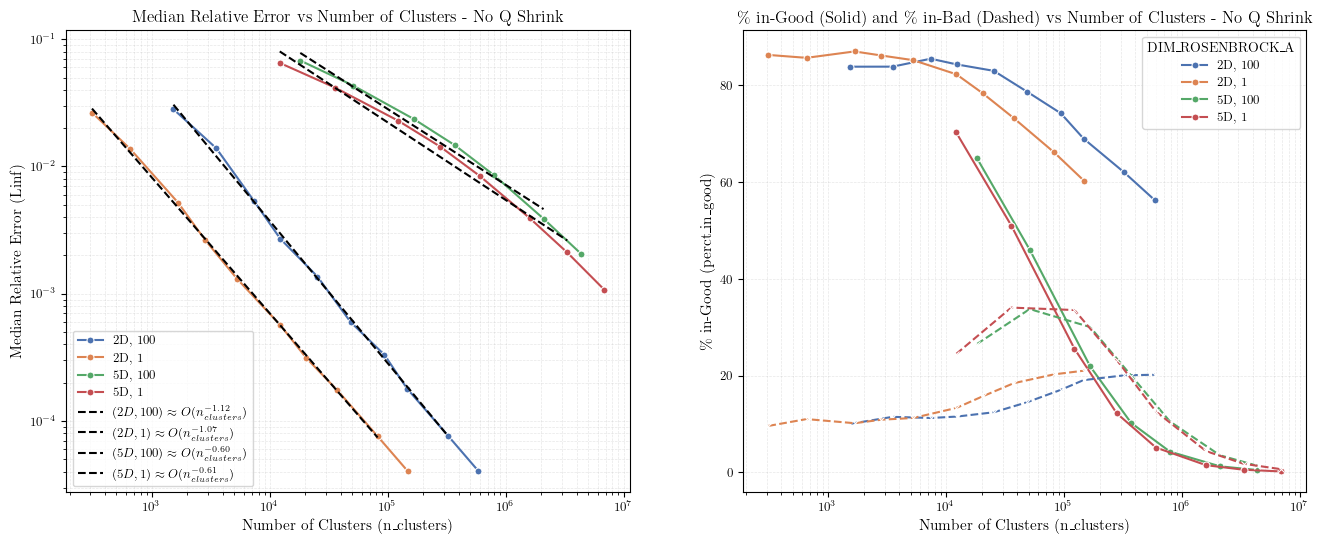

In [46]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_rosen,
    x="n_clusters",
    y="median_rel_error_linf",
    hue="DIM_ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)
# Fit linear regression lines (in log-log space) for each dimension
for group in df_rosen["DIM_ROSENBROCK_A"].unique():
    subset = df_rosen[df_rosen["DIM_ROSENBROCK_A"] == group]
    X = np.log(subset["n_clusters"].values).reshape(-1, 1)
    y = np.log(subset["median_rel_error_linf"].values)
    # Drop the last point to avoid outlier influence
    X = X[:-1]
    y = y[:-1]
    model = LinearRegression()
    model.fit(X, y)
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    label = rf"$({group}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.plot(np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel("Median Relative Error (Linf)")
plt.title("Median Relative Error vs Number of Clusters - No Q Shrink")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_rosen,
    x="n_clusters",
    y="perct_in_good",
    hue="DIM_ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)
sns.lineplot(
    data=df_rosen,
    x="n_clusters",
    y="perct_in_bad",
    hue="DIM_ROSENBROCK_A",
    marker="x",
    palette=PALETTE,
    linestyle="--",
    legend=False,
    label="_nolegend_",
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ in-Good (perct_in_good)")
plt.title(
    r"$\%$ in-Good (Solid) and $\%$ in-Bad (Dashed) vs Number of Clusters - No Q Shrink"
)
plt.grid(True, which="both", ls="--", lw=0.5)

In [ ]:
col_mapper = {
    "dim": "D",
    "tol": "tol",
    "ROSENBROCK_A": "Rosenbrock_A",
    "n_clusters": "N_src",
    "max_rel_error_linf": "max_e_linf",
    "median_rel_error_linf": "median_e_linf",
    "max_rel_error_l2": "max_e_l2",
    "median_rel_error_l2": "median_e_l2",
    "perct_out": r"%_out",
    "perct_in_good": r"%_in_good",
    "perct_in_bad": r"%_in_bad",
    "n_train": "n_train",
    "n_test": "n_test",
}
df_rosen_renamed = df_rosen.rename(columns=col_mapper)[list(col_mapper.values())]
df_rosen_renamed.to_clipboard(index=False)
df_rosen_renamed

,D,tol,Rosenbrock_A,N_src,max_e_linf,median_e_linf,max_e_l2,median_e_l2,%_out,%_in_good,%_in_bad,n_train,n_test
0,2,0.1000,100,1521,1.307549,0.028175,1.307549,0.028175,6.102,83.886,10.012,200000,100000
1,2,0.1000,1,310,0.725633,0.026545,0.725633,0.026545,4.083,86.320,9.597,200000,100000
2,2,0.0500,1,653,0.531379,0.013751,0.531379,0.013751,3.273,85.716,11.011,200000,100000
3,2,0.0500,100,3506,0.724518,0.013918,0.724518,0.013918,4.632,83.893,11.475,200000,100000
4,2,0.0200,100,7376,0.343938,0.005309,0.343938,0.005309,3.226,85.535,11.239,200000,100000
5,2,0.0200,1,1667,0.109864,0.005188,0.109864,0.005188,2.799,87.041,10.160,200000,100000
6,2,0.0100,100,12260,0.150674,0.002700,0.150674,0.002700,4.114,84.356,11.530,200000,100000
7,2,0.0100,1,2822,0.106502,0.002645,0.106502,0.002645,2.916,86.196,10.888,200000,100000
8,2,0.0050,100,25271,0.063889,0.001365,0.063889,0.001365,4.555,83.026,12.419,200000,100000
9,2,0.0050,1,5238,0.057547,0.001317,0.057547,0.001317,3.525,85.236,11.239,200000,100000
